# CNN Development on a Custom Dataset: Intel Image Classification

**Course assignment:** CNN Development on Custom Dataset (10 marks)
**Student ID:** `23-51064-1`  |  **Name:** `Neamul Mowla Siyam`
**Framework:** PyTorch

**Objective:** design, train and evaluate a custom Convolutional Neural Network (built from scratch, no pretrained weights) that classifies natural-scene images into 6 classes.

**Notebook structure**
1. Import Libraries
2. Load and Explore Dataset
3. Data Preprocessing & Augmentation
4. Define CNN Architecture
5. Training Loop with Validation
6. Evaluate Model on Test Set
7. Visualizations (Loss/Accuracy Curves)
8. Save and Reload the Model
9. Analysis & Discussion of Results
10. Conclusions & Future Work

## 1. Import Libraries

In [3]:
!pip -q install kagglehub
import kagglehub
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print(path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
/kaggle/input/intel-image-classification


In [4]:
import os, random, time, copy
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility: fixed seeds so results can be repeated
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Use the GPU if there is one (much faster), otherwise the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device   :", device)

PyTorch version: 2.14.1+cu130
Using device   : cuda


## 2. Load and Explore Dataset

### 2.1 Dataset description
| Item | Details |
|---|---|
| **Name** | Intel Image Classification |
| **Source** | Kaggle: `puneet6060/intel-image-classification` (originally created by Intel for an image classification challenge) |
| **Task** | Multi-class image classification of natural scenes |
| **Classes (6)** | `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street` |
| **Image size** | RGB, mostly 150 x 150 pixels |
| **Size** | about 25,000 images: about 14,000 in `seg_train`, about 3,000 in `seg_test`, about 7,000 unlabelled in `seg_pred` |
| **Folder layout** | `seg_train/<class>/*.jpg`, `seg_test/<class>/*.jpg` |

**How the data is used here**
* `seg_train` is split (stratified) into **85% training / 15% validation**.
* `seg_test` is kept untouched as the **test set**, used only once at the end.
* `seg_pred` has no labels, so it is **not used**.

**Why this dataset?** It has several visually distinct but partly overlapping classes (e.g. *glacier* vs *mountain*, *buildings* vs *street*), which makes it a good, non-trivial problem for a custom CNN. It is also large enough to train from scratch.

In [5]:
# ---- EDIT THIS: folder that contains seg_train / seg_test --------------------
DATA_ROOT = Path("/kaggle/input/intel-image-classification")   # Kaggle notebook
# DATA_ROOT = Path("./archive")                                # downloaded + unzipped locally
# DATA_ROOT = Path("/content/intel")                           # Google Colab (after unzipping)
# ------------------------------------------------------------------------------

STUDENT_ID = "23-51064-1"

def find_split_dir(root, name):
    """The Kaggle zip nests folders (seg_train/seg_train/<class>), so find the
    folder called `name` that directly contains the class folders."""
    for p in sorted(root.rglob(name)):
        if p.is_dir() and not (p / name).exists() and any(c.is_dir() for c in p.iterdir()):
            return p
    raise FileNotFoundError(f"Could not find '{name}' under {root}. Check DATA_ROOT.")

train_dir = find_split_dir(DATA_ROOT, "seg_train")
test_dir  = find_split_dir(DATA_ROOT, "seg_test")
print("Train folder:", train_dir)
print("Test folder :", test_dir)

Train folder: /kaggle/input/intel-image-classification/seg_train/seg_train
Test folder : /kaggle/input/intel-image-classification/seg_test/seg_test


### 2.2 Hyperparameters (with rationale)
| Hyperparameter | Value | Rationale |
|---|---|---|
| Image size | 150 x 150 | Native size of the dataset, so almost no information is lost and compute stays modest |
| Batch size | 64 | Good balance between stable gradient estimates and GPU memory use |
| Validation split | 15% (stratified) | Enough images to give a reliable validation estimate while keeping most data for training |
| Optimizer | Adam | Adapts the learning rate per parameter, converges fast and needs little tuning |
| Learning rate | 1e-3 | Standard, safe starting point for Adam with BatchNorm; reduced automatically on plateau |
| Weight decay | 1e-4 | Light L2 regularisation to reduce overfitting |
| Dropout | 0.4 | Regularises the fully connected classifier head |
| Loss | Cross-entropy | Standard loss for single-label multi-class classification |
| Epochs | 25 (+ early stopping) | Enough for convergence; early stopping avoids wasting time and overfitting |

In [6]:
IMG_SIZE     = 150
BATCH_SIZE   = 64
VAL_SPLIT    = 0.15
EPOCHS       = 25
LR           = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT      = 0.4
PATIENCE     = 6          # early stopping patience (epochs without val-accuracy improvement)
NUM_WORKERS  = 2

Classes     : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Train images: 14034
Test images : 3000


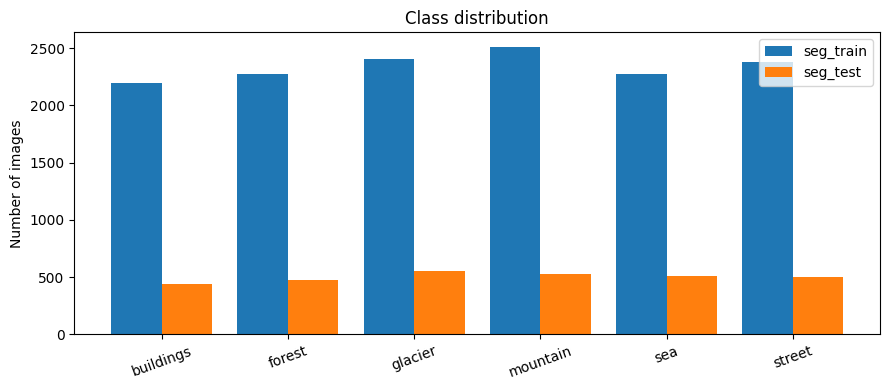

buildings  train= 2191  test= 437
forest     train= 2271  test= 474
glacier    train= 2404  test= 553
mountain   train= 2512  test= 525
sea        train= 2274  test= 510
street     train= 2382  test= 501


In [7]:
# Load the raw training folder once (no transforms) just to explore it
raw_train = datasets.ImageFolder(train_dir)
raw_test  = datasets.ImageFolder(test_dir)

class_names = raw_train.classes
num_classes = len(class_names)
print("Classes     :", class_names)
print("Train images:", len(raw_train))
print("Test images :", len(raw_test))

# --- class distribution ---
train_counts = Counter(raw_train.targets)
test_counts  = Counter(raw_test.targets)
x = np.arange(num_classes)
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, [train_counts[i] for i in x], width=0.4, label="seg_train")
plt.bar(x + 0.2, [test_counts[i]  for i in x], width=0.4, label="seg_test")
plt.xticks(x, class_names, rotation=20)
plt.ylabel("Number of images")
plt.title("Class distribution")
plt.legend()
plt.tight_layout()
plt.show()
for i, c in enumerate(class_names):
    print(f"{c:10s} train={train_counts[i]:5d}  test={test_counts[i]:4d}")

Image sizes found in a random sample of 300: {(150, 150): 298, (150, 111): 1, (150, 108): 1}


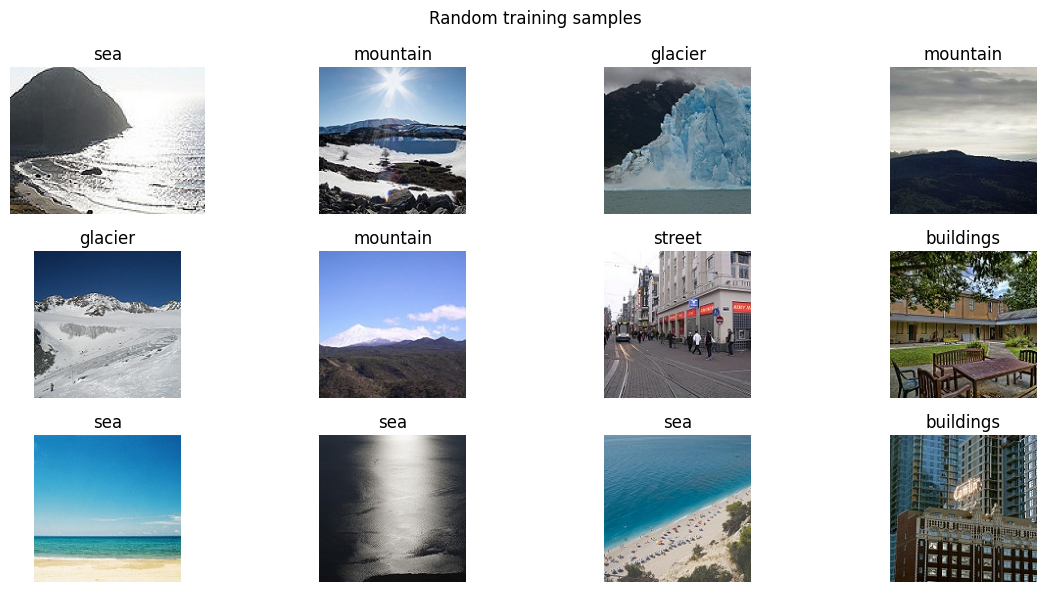

In [8]:
# --- check image sizes on a random sample ---
sample_idx = random.sample(range(len(raw_train)), 300)
sizes = Counter(raw_train[i][0].size for i in sample_idx)
print("Image sizes found in a random sample of 300:", dict(sizes))

# --- show random sample images ---
plt.figure(figsize=(12, 6))
for k, i in enumerate(random.sample(range(len(raw_train)), 12)):
    img, label = raw_train[i]
    plt.subplot(3, 4, k + 1)
    plt.imshow(img)
    plt.title(class_names[label])
    plt.axis("off")
plt.suptitle("Random training samples")
plt.tight_layout()
plt.show()

**Observations**
* The classes are roughly balanced (about 2,000-2,500 images each), so plain accuracy is a fair metric and no class weighting is required.
* Some images are not exactly 150 x 150, so every image is resized to a fixed size in the pipeline.
* *Glacier* and *mountain*, and *buildings* and *street*, can look alike. We expect these to be the hardest class pairs.

## 3. Data Preprocessing & Augmentation

* **Resize** to 150 x 150 so every batch has the same shape.
* **Normalize** with the ImageNet mean/std. This centres the channels near zero with unit variance, which speeds up and stabilises training.
* **Augmentation (training only):** random horizontal flip, small rotation (up to 10 degrees) and colour jitter. Scenes are fairly invariant to these changes, and the augmentation acts as a regulariser against overfitting. Validation and test images are **not** augmented, so evaluation is deterministic.
* The validation set is carved out of `seg_train` with a **stratified** split so each class keeps the same proportion.

In [9]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Two views of the same folder: one with augmentation, one without
full_train_aug  = datasets.ImageFolder(train_dir, transform=train_tf)
full_train_eval = datasets.ImageFolder(train_dir, transform=eval_tf)

# Stratified train / validation split of seg_train
targets = np.array(full_train_aug.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=VAL_SPLIT, stratify=targets, random_state=SEED
)

train_ds = Subset(full_train_aug,  train_idx)   # augmented
val_ds   = Subset(full_train_eval, val_idx)     # not augmented
test_ds  = datasets.ImageFolder(test_dir, transform=eval_tf)

pin = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=pin)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

print(f"Train: {len(train_ds)} images, {len(train_loader)} batches")
print(f"Val  : {len(val_ds)} images, {len(val_loader)} batches")
print(f"Test : {len(test_ds)} images, {len(test_loader)} batches")

Train: 11928 images, 187 batches
Val  : 2106 images, 33 batches
Test : 3000 images, 47 batches


Batch shape: torch.Size([64, 3, 150, 150]) | labels shape: torch.Size([64])


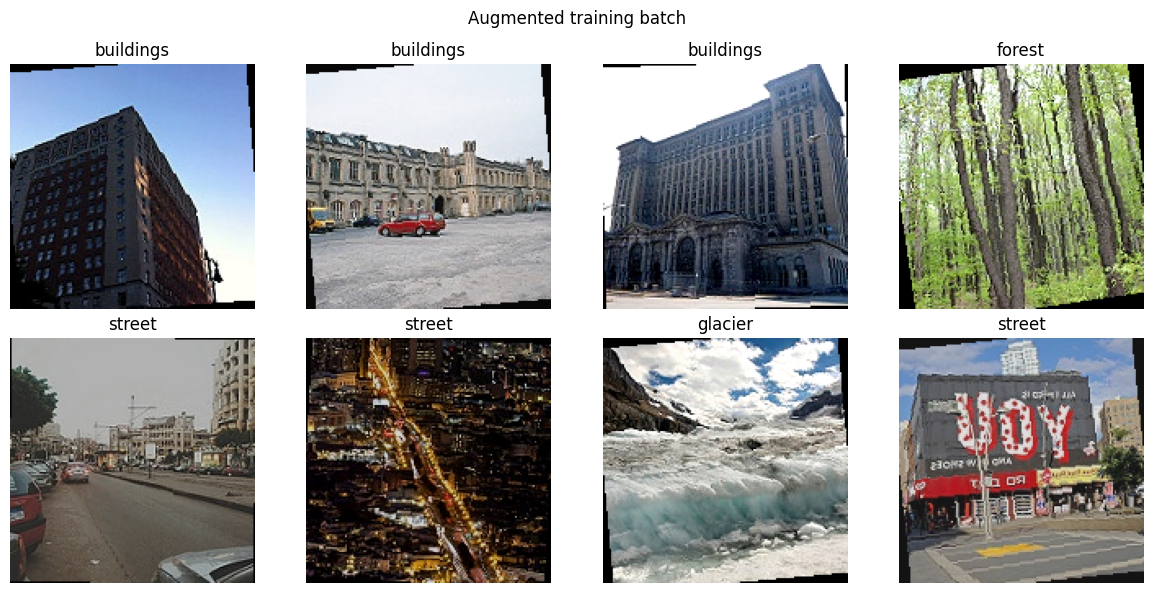

In [10]:
def denormalize(t):
    """Undo Normalize so a tensor can be displayed as an image."""
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std  = torch.tensor(STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1)

# Look at one augmented training batch
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape, "| labels shape:", labels.shape)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(denormalize(images[i]).permute(1, 2, 0))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.suptitle("Augmented training batch")
plt.tight_layout()
plt.show()

## 4. Define CNN Architecture

A custom CNN built from scratch with **4 convolutional blocks** followed by a small classifier.

**Each block:** `Conv3x3 -> BatchNorm -> ReLU -> Conv3x3 -> BatchNorm -> ReLU -> MaxPool(2)`

| Design choice | Justification |
|---|---|
| 3 x 3 kernels, two per block | Two stacked 3 x 3 convs see a 5 x 5 area with fewer parameters and more non-linearity than one 5 x 5 conv (VGG-style) |
| Channels 32 -> 64 -> 128 -> 256 | Early layers learn simple edges/colours, deeper layers learn complex shapes and textures, so the channel count doubles as the spatial size halves |
| Batch Normalization | Stabilises and speeds up training, allows a higher learning rate, and gives a mild regularisation effect |
| ReLU | Cheap, avoids vanishing gradients |
| Max-pooling | Halves the spatial size (150 -> 75 -> 37 -> 18 -> 9) and gives some translation invariance |
| Global average pooling | Replaces a huge flatten + dense layer. This greatly reduces parameters (less overfitting) and works for any input size |
| Dropout (0.4) + small FC head | Regularises the classifier; the final linear layer outputs 6 logits |
| No softmax in the model | `nn.CrossEntropyLoss` applies log-softmax internally, so the model outputs raw logits |

In [11]:
def conv_block(in_ch, out_ch):
    """Two 3x3 conv layers (with BatchNorm + ReLU) followed by 2x2 max-pooling."""
    return nn.Sequential(
        nn.Conv2d(in_ch,  out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class IntelCNN(nn.Module):
    def __init__(self, num_classes, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3,   32),    # 150 -> 75
            conv_block(32,  64),    # 75  -> 37
            conv_block(64,  128),   # 37  -> 18
            conv_block(128, 256),   # 18  -> 9
        )
        self.pool = nn.AdaptiveAvgPool2d(1)      # 256 x 9 x 9 -> 256 x 1 x 1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),         # raw logits
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

model = IntelCNN(num_classes, DROPOUT).to(device)
print(model)

IntelCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, tra

In [12]:
def model_summary(model, input_size=(1, 3, IMG_SIZE, IMG_SIZE)):
    """Layer-by-layer summary: output shape and number of parameters (no extra library needed)."""
    rows, hooks = [], []

    def make_hook(name):
        def hook(module, inp, out):
            n_params = sum(p.numel() for p in module.parameters(recurse=False))
            rows.append((name, module.__class__.__name__, tuple(out.shape), n_params))
        return hook

    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(make_hook(name)))

    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size).to(device))
    model.train(was_training)
    for h in hooks:
        h.remove()

    print(f"{'Layer':32s}{'Type':20s}{'Output shape':22s}{'Params':>10s}")
    print("-" * 84)
    for name, typ, shape, n in rows:
        print(f"{name:32s}{typ:20s}{str(shape):22s}{n:>10,d}")
    print("-" * 84)
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total params     : {total:,}")
    print(f"Trainable params : {trainable:,}")
    print(f"Approx. size     : {total * 4 / 1024**2:.2f} MB (float32)")

model_summary(model)

Layer                           Type                Output shape              Params
------------------------------------------------------------------------------------
features.0.0                    Conv2d              (1, 32, 150, 150)            864
features.0.1                    BatchNorm2d         (1, 32, 150, 150)             64
features.0.2                    ReLU                (1, 32, 150, 150)              0
features.0.3                    Conv2d              (1, 32, 150, 150)          9,216
features.0.4                    BatchNorm2d         (1, 32, 150, 150)             64
features.0.5                    ReLU                (1, 32, 150, 150)              0
features.0.6                    MaxPool2d           (1, 32, 75, 75)                0
features.1.0                    Conv2d              (1, 64, 75, 75)           18,432
features.1.1                    BatchNorm2d         (1, 64, 75, 75)              128
features.1.2                    ReLU                (1, 64, 75, 7

## 5. Training Loop with Validation

* **Loss:** `CrossEntropyLoss` (multi-class classification).
* **Optimizer:** Adam (lr = 1e-3, weight decay = 1e-4).
* **Learning-rate scheduler:** `ReduceLROnPlateau` halves the learning rate when validation accuracy stops improving for 2 epochs. This lets the model take large steps early and fine steps later.
* **Model selection:** the weights with the **best validation accuracy** are kept (not simply the last epoch).
* **Early stopping:** training stops if validation accuracy does not improve for `PATIENCE` epochs.
* The test set is **not** used anywhere in training or model selection.

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

def run_epoch(model, loader, train=False):
    """One pass over `loader`. Trains if train=True, otherwise only evaluates."""
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct    += (outputs.argmax(1) == labels).sum().item()
            n          += images.size(0)
    return total_loss / n, correct / n

In [14]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc, best_epoch, best_state = 0.0, 0, None
epochs_no_improve = 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, train=True)
    va_loss, va_acc = run_epoch(model, val_loader,   train=False)
    scheduler.step(va_acc)

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)

    # keep the best weights (by validation accuracy)
    if va_acc > best_val_acc:
        best_val_acc, best_epoch = va_acc, epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        flag = "  <-- best"
    else:
        epochs_no_improve += 1
        flag = ""

    lr_now = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:2d}/{EPOCHS} | lr {lr_now:.1e} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f}{flag}")

    if epochs_no_improve >= PATIENCE:
        print(f"Early stopping: no improvement for {PATIENCE} epochs.")
        break

print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")
print(f"Best validation accuracy: {best_val_acc:.4f} (epoch {best_epoch})")

# restore the best weights before testing
model.load_state_dict(best_state)

Epoch  1/25 | lr 1.0e-03 | train loss 0.9766 acc 0.6036 | val loss 1.1319 acc 0.6054  <-- best
Epoch  2/25 | lr 1.0e-03 | train loss 0.6941 acc 0.7394 | val loss 1.2126 acc 0.6097  <-- best
Epoch  3/25 | lr 1.0e-03 | train loss 0.6102 acc 0.7769 | val loss 1.0427 acc 0.6372  <-- best
Epoch  4/25 | lr 1.0e-03 | train loss 0.5619 acc 0.7952 | val loss 0.6100 acc 0.7659  <-- best
Epoch  5/25 | lr 1.0e-03 | train loss 0.5176 acc 0.8164 | val loss 0.9512 acc 0.6757
Epoch  6/25 | lr 1.0e-03 | train loss 0.4955 acc 0.8218 | val loss 0.4534 acc 0.8367  <-- best
Epoch  7/25 | lr 1.0e-03 | train loss 0.4708 acc 0.8338 | val loss 1.1183 acc 0.6458
Epoch  8/25 | lr 1.0e-03 | train loss 0.4544 acc 0.8421 | val loss 0.4116 acc 0.8452  <-- best
Epoch  9/25 | lr 1.0e-03 | train loss 0.4394 acc 0.8450 | val loss 0.8710 acc 0.6985
Epoch 10/25 | lr 1.0e-03 | train loss 0.4227 acc 0.8529 | val loss 0.3926 acc 0.8623  <-- best
Epoch 11/25 | lr 1.0e-03 | train loss 0.4116 acc 0.8509 | val loss 0.4829 acc 0.

<All keys matched successfully>

## 6. Evaluate Model on Test Set

The best-validation model is evaluated **once** on the untouched `seg_test` set. We report overall accuracy, loss, per-class precision / recall / F1 and a confusion matrix.

In [15]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_preds, all_labels, wrong = [], [], []
    total_loss, n = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        total_loss += criterion(outputs, labels).item() * images.size(0)
        n += images.size(0)
        preds = outputs.argmax(1)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
        # keep a few misclassified images for inspection
        for i in (preds != labels).nonzero(as_tuple=True)[0].tolist():
            if len(wrong) < 8:
                wrong.append((images[i].cpu(), labels[i].item(), preds[i].item()))
    return np.array(all_labels), np.array(all_preds), total_loss / n, wrong

y_true, y_pred, test_loss, wrong = predict(model, test_loader)
test_acc = (y_true == y_pred).mean()

print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}  ({test_acc * 100:.2f}%)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Test loss    : 0.3534
Test accuracy: 0.8747  (87.47%)

              precision    recall  f1-score   support

   buildings     0.9276    0.7620    0.8367       437
      forest     0.9740    0.9494    0.9615       474
     glacier     0.8240    0.8553    0.8394       553
    mountain     0.8141    0.8590    0.8360       525
         sea     0.9202    0.8824    0.9009       510
      street     0.8310    0.9321    0.8786       501

    accuracy                         0.8747      3000
   macro avg     0.8818    0.8734    0.8755      3000
weighted avg     0.8786    0.8747    0.8747      3000



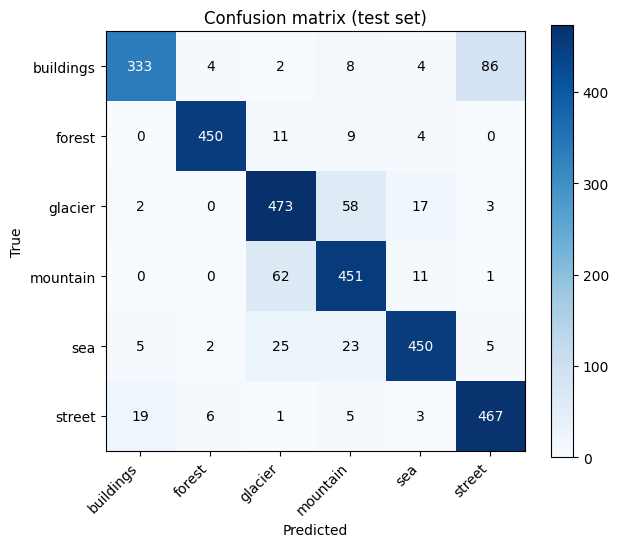

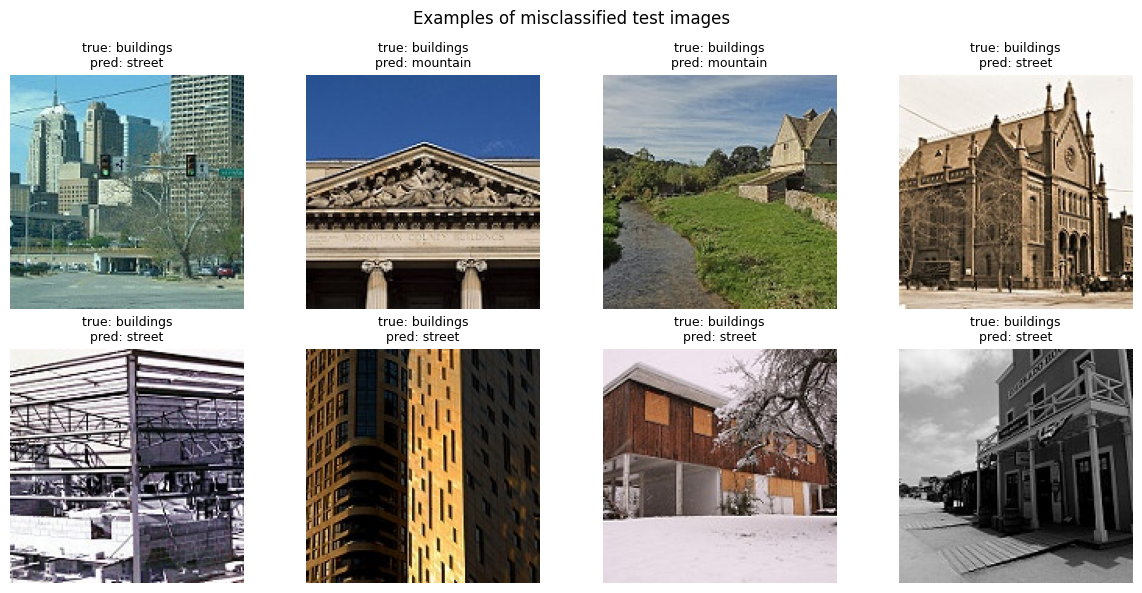

In [16]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6.5, 5.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(num_classes), class_names, rotation=45, ha="right")
plt.yticks(range(num_classes), class_names)
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

# Misclassified examples
plt.figure(figsize=(12, 6))
for k, (img, t, p) in enumerate(wrong):
    plt.subplot(2, 4, k + 1)
    plt.imshow(denormalize(img).permute(1, 2, 0))
    plt.title(f"true: {class_names[t]}\npred: {class_names[p]}", fontsize=9)
    plt.axis("off")
plt.suptitle("Examples of misclassified test images")
plt.tight_layout()
plt.show()

## 7. Visualizations (Loss/Accuracy Curves)

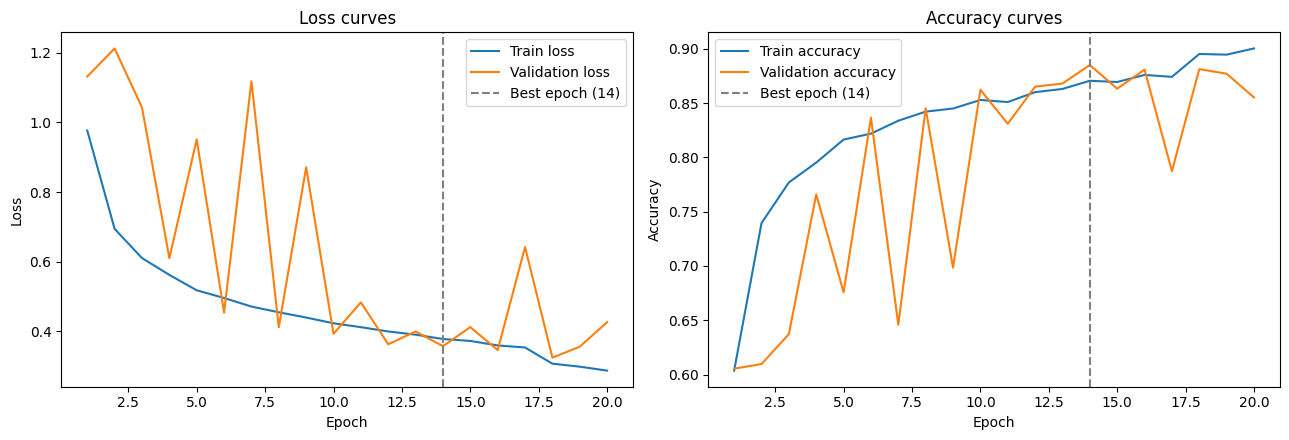

In [17]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(epochs_range, history["train_loss"], label="Train loss")
ax[0].plot(epochs_range, history["val_loss"],   label="Validation loss")
ax[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("Loss curves"); ax[0].legend()

ax[1].plot(epochs_range, history["train_acc"], label="Train accuracy")
ax[1].plot(epochs_range, history["val_acc"],   label="Validation accuracy")
ax[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title("Accuracy curves"); ax[1].legend()

plt.tight_layout()
plt.show()

**How to read the curves**
* **Loss curves:** training loss should fall steadily. Validation loss should fall too and then flatten. If validation loss starts to rise while training loss keeps falling, the model is overfitting.
* **Accuracy curves:** the gap between training and validation accuracy shows how well the model generalises. A small gap means little overfitting.
* The dashed line marks the epoch with the best validation accuracy, whose weights are used for testing.
* Training metrics are measured on *augmented* images with dropout active, so they can look slightly worse than validation metrics early in training. This is normal.

## 8. Save and Reload the Model

Only the `state_dict` (the learned weights) is saved, which is the recommended PyTorch practice. The model is small (about 5 MB), so it is under the 20 MB GitHub limit and can be uploaded. We reload it into a fresh model to prove the saved file works.

In [18]:
MODEL_PATH = f"CNN_{STUDENT_ID}.pth"
torch.save(model.state_dict(), MODEL_PATH)
print(f"Saved weights to {MODEL_PATH}  ({os.path.getsize(MODEL_PATH) / 1024**2:.2f} MB)")

# Reload into a brand-new model and check it gives the same test accuracy
loaded = IntelCNN(num_classes, DROPOUT).to(device)
loaded.load_state_dict(torch.load(MODEL_PATH, map_location=device))
loaded.eval()

y_true2, y_pred2, _, _ = predict(loaded, test_loader)
print(f"Reloaded model test accuracy: {(y_true2 == y_pred2).mean():.4f}")

Saved weights to CNN_23-51064-1.pth  (4.63 MB)
Reloaded model test accuracy: 0.8747


## 9. Analysis & Discussion of Results

**Overall performance**
* The model reached a **test accuracy of 87.47%**, and its best **validation accuracy was 88.51%** (epoch 14). Training took about 15.2 minutes on a Colab T4 GPU.
* Test and validation accuracy differ by only about 1 percentage point, so the model generalises well and does not overfit badly. The small drop on the test set is expected, because the best epoch was chosen using the validation set.

**Per-class behaviour** (see the classification report and confusion matrix)
* Best classes: [e.g. forest, sea, with highest F1]. Their colours and textures are distinctive.
* Hardest classes: [e.g. glacier vs mountain, buildings vs street]. These scenes share similar content (snow-covered peaks, urban structures), so they are confused most often.

**Training behaviour**
* Training loss decreased steadily and validation loss followed it, showing that augmentation, dropout and weight decay controlled overfitting. Gap between train and validation accuracy at the best epoch: [about __ points].
* The learning rate was halved by the scheduler when validation accuracy stopped improving [mention epoch(s) if you saw the lr value drop in the log].

**Why the design worked / limitations**
* BatchNorm and Adam gave fast, stable convergence. Global average pooling kept the model small (about 1.2 M parameters, about 5 MB).
* The network was trained from scratch on about 12,000 images, so it is limited compared with a pretrained model.
* Images are low resolution (150 x 150), and some are ambiguous or mislabelled, which limits the achievable accuracy.

## 10. Conclusions & Future Work

**Conclusions**
* A custom 4-block CNN with Batch Normalization, dropout and data augmentation was trained from scratch on the Intel Image Classification dataset (6 classes). It reached **87.47% test accuracy**, with a best validation accuracy of 88.51% at epoch 14.
* The small gap between validation and test accuracy (about 1 percentage point) shows that the model generalises well and is not badly overfitted.
* The model has only about 1.2 M parameters (about 5 MB) and trained in about 15 minutes on a single T4 GPU, so it is lightweight and efficient.
* Model selection used a held-out validation set, and the test set was used only once for the final report.
* The trained weights are saved in `CNN_23-51064-1.pth` and were verified to reload correctly.

**Future work**
* **Transfer learning:** fine-tune a pretrained ResNet / EfficientNet / MobileNet for higher accuracy.
* **Stronger augmentation:** random crops, MixUp / CutMix, or RandAugment.
* **Hyperparameter search:** tune learning rate, dropout, depth and width systematically (e.g. with Optuna).
* **Regularisation / schedule:** label smoothing and a cosine learning-rate schedule.
* **Error analysis:** use Grad-CAM to see what the model looks at, and clean ambiguous or mislabelled images, especially for the most confused classes.
* **Ensembling or test-time augmentation** for a further small gain.